# 01 — Análise exploratória: churn por inatividade na VAI Store

**PTC3567 — Ciência dos Dados · Grupo 4** · notebook 1 de 2 (o notebook 2 trata da engenharia de atributos e da modelagem).

**Objetivo.** Caracterizar a base de vendas cedida pela Visagio, avaliar sua qualidade e explorar a dinâmica de recompra dos clientes para
(i) fundamentar o **critério de churn por inatividade** e (ii) investigar, de forma preliminar, as hipóteses comportamentais H3–H9.
Questões de pesquisa e hipóteses: [`docs/questoes_e_hipoteses.md`](../docs/questoes_e_hipoteses.md).

**Roteiro** (segue o pipeline de EDA da disciplina: caracterização → qualidade → estatística descritiva → relações entre variáveis):

1. Proveniência e integridade dos dados
2. Caracterização: tipos de atributos e granularidade
3. Qualidade dos dados
4. Estatística descritiva
5. Dinâmica temporal e sazonalidade
6. Visão do cliente
7. Coortes de aquisição e retenção
8. Intervalo entre visitas e análise de sobrevivência
9. Critério de inatividade (H1)
10. Hipóteses comportamentais no snapshot de treino (H3–H9)
11. Síntese e decisões para a modelagem

> **Cuidado com *data snooping*.** As seções 2–9 descrevem a base inteira. A seção 10, que olha para o rótulo de churn,
> usa só o snapshot de **01/05/2024**, que está no conjunto de treino de todas as validações do notebook 2.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from sklearn.metrics import cohen_kappa_score

from churn import config, data, features, evaluation as ev, viz

viz.aplicar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", viz.fmt_tabela)

DIAS_SEMANA = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

## 1. Proveniência e integridade dos dados

Os dados foram cedidos pela Visagio (case **VAI Store**, varejo alimentar saudável) e **não são públicos** — por isso não
são versionados no repositório (`data/raw/` está no `.gitignore`). Para garantir que todos os integrantes analisem
exatamente os mesmos arquivos, registramos tamanho e hash SHA-256 de cada um; qualquer alteração nos dados muda o hash.

In [2]:
brutos = {"vendas.csv": config.ARQ_VENDAS, "produto.csv": config.ARQ_PRODUTOS}
vendas = data.ler_vendas()
produtos = data.ler_produtos()

pd.DataFrame(
    {
        "linhas": [len(vendas), len(produtos)],
        "colunas": [vendas.shape[1], produtos.shape[1]],
        "tamanho (MB)": [p.stat().st_size / 1e6 for p in brutos.values()],
        "SHA-256": [data.sha256(p) for p in brutos.values()],
    },
    index=pd.Index(list(brutos), name="arquivo"),
)

,linhas,colunas,tamanho (MB),SHA-256
arquivo,,,,
vendas.csv,556198,10,"71,303",4a4560758c71aa265072fad0da05547d004539e3eb44be...
produto.csv,6500,4,"0,609",5216141e648fc2716994ca3739567a63788946d3c21c4a...


## 2. Caracterização dos dados

### 2.1 Dicionário e tipos de atributos

Classificação segundo a aula de EDA: **quantitativos** (contínuos ou discretos) e **qualitativos** (nominais ou ordinais).
Atenção à armadilha clássica: `COD_FILIAL`, `SKU` e os códigos de atendimento são números, mas são **identificadores
nominais** — médias ou somas sobre eles não têm significado.

In [3]:
tipos = {
    "COD_ATEND": ("Qualitativo", "Nominal (identificador)", "Atendimento (cupom)"),
    "COD_VENDA": ("Qualitativo", "Nominal (identificador)", "Item vendido — chave da linha"),
    "COD_FILIAL": ("Qualitativo", "Nominal (identificador)", "Código da loja"),
    "FILIAL": ("Qualitativo", "Nominal", "Tipo de loja (RUA ou SHOPPING)"),
    "DATA_ATEND": ("Quantitativo", "Intervalar (data)", "Dia do atendimento"),
    "SKU": ("Qualitativo", "Nominal (identificador)", "Código do produto"),
    "UNID": ("Qualitativo", "Nominal", "Unidade de venda: KG (granel) ou UN"),
    "QTD_VENDA": ("Quantitativo", "Contínuo (razão)", "Quantidade vendida (kg ou unidades)"),
    "FATUR_VENDA": ("Quantitativo", "Contínuo (razão)", "Faturamento do item (R$)"),
    "CLI_CPF": ("Qualitativo", "Nominal (identificador)", "Cliente (código anonimizado)"),
    "NOME_PRODUTO": ("Qualitativo", "Nominal", "Descrição do produto"),
    "CATEGORIA": ("Qualitativo", "Nominal", "Categoria do produto"),
    "SUBCATEGORIA": ("Qualitativo", "Nominal", "Subcategoria do produto"),
}
linhas = []
for col, (tipo, subtipo, descricao) in tipos.items():
    df, tabela = (vendas, "vendas") if col in vendas else (produtos, "produto")
    linhas.append({
        "atributo": col, "tabela": tabela, "tipo": tipo, "subtipo": subtipo, "descrição": descricao,
        "valores distintos": df[col].nunique(), "exemplo": str(df[col].dropna().iloc[0]),
    })
pd.DataFrame(linhas).set_index("atributo")

,tabela,tipo,subtipo,descrição,valores distintos,exemplo
atributo,,,,,,
COD_ATEND,vendas,Qualitativo,Nominal (identificador),Atendimento (cupom),302228,000304564.299.0101042.20240102
COD_VENDA,vendas,Qualitativo,Nominal (identificador),Item vendido — chave da linha,556198,000304564.299.0101042.20240102.000009.02
COD_FILIAL,vendas,Qualitativo,Nominal (identificador),Código da loja,2,101042
FILIAL,vendas,Qualitativo,Nominal,Tipo de loja (RUA ou SHOPPING),2,SHOPPING
DATA_ATEND,vendas,Quantitativo,Intervalar (data),Dia do atendimento,362,2024-01-02 00:00:00
SKU,vendas,Qualitativo,Nominal (identificador),Código do produto,59,9
UNID,vendas,Qualitativo,Nominal,Unidade de venda: KG (granel) ou UN,2,KG
QTD_VENDA,vendas,Quantitativo,Contínuo (razão),Quantidade vendida (kg ou unidades),2412,0.258
FATUR_VENDA,vendas,Quantitativo,Contínuo (razão),Faturamento do item (R$),11759,18.04


### 2.2 Granularidade e chaves

Cada linha é **um item vendido**; vários itens formam um **atendimento** (cupom). Verificamos a consistência das chaves e
definimos a unidade de análise do churn: a **visita**, isto é, o par cliente-dia. Alguns clientes têm mais de um
atendimento no mesmo dia; para medir recorrência, isso conta como uma única ida à loja.

In [4]:
por_atend = vendas.groupby("COD_ATEND").agg(
    clientes=("CLI_CPF", "nunique"), datas=("DATA_ATEND", "nunique"), lojas=("COD_FILIAL", "nunique")
)
display(pd.Series({
    "COD_VENDA é único (1 linha = 1 item vendido)": vendas["COD_VENDA"].is_unique,
    "cada atendimento tem um único cliente": por_atend["clientes"].eq(1).all(),
    "cada atendimento ocorre em uma única data": por_atend["datas"].eq(1).all(),
    "cada atendimento ocorre em uma única loja": por_atend["lojas"].eq(1).all(),
    "COD_FILIAL e FILIAL são 1:1": vendas.groupby("COD_FILIAL")["FILIAL"].nunique().eq(1).all(),
    "todo SKU vendido existe no cadastro": vendas["SKU"].isin(produtos["SKU"]).all(),
}, name="verificação").to_frame())

atend_por_dia = vendas.groupby(["CLI_CPF", "DATA_ATEND"])["COD_ATEND"].nunique()
pd.Series({
    "itens vendidos (linhas)": len(vendas),
    "atendimentos": vendas["COD_ATEND"].nunique(),
    "visitas (cliente-dia)": len(atend_por_dia),
    "visitas com mais de um atendimento": int((atend_por_dia > 1).sum()),
    "clientes": vendas["CLI_CPF"].nunique(),
    "SKUs vendidos": vendas["SKU"].nunique(),
    "SKUs no cadastro": produtos["SKU"].nunique(),
    "lojas": vendas["COD_FILIAL"].nunique(),
    "dias com venda": vendas["DATA_ATEND"].nunique(),
}, name="quantidade").to_frame()

,verificação
COD_VENDA é único (1 linha = 1 item vendido),True
cada atendimento tem um único cliente,True
cada atendimento ocorre em uma única data,True
cada atendimento ocorre em uma única loja,True
COD_FILIAL e FILIAL são 1:1,True
todo SKU vendido existe no cadastro,True


,quantidade
itens vendidos (linhas),556198
atendimentos,302228
visitas (cliente-dia),297257
visitas com mais de um atendimento,4754
clientes,102943
SKUs vendidos,59
SKUs no cadastro,6499
lojas,2
dias com venda,362


## 3. Qualidade dos dados

### 3.1 Valores ausentes, duplicidades e domínio

In [5]:
def resumo_ausentes(df, nome):
    return pd.DataFrame({"tabela": nome, "ausentes": df.isna().sum(), "% ausente": df.isna().mean()})

display(pd.concat([resumo_ausentes(vendas, "vendas"), resumo_ausentes(produtos, "produto")]))

vendidos = produtos[produtos["SKU"].isin(vendas["SKU"])]
pd.Series({
    "linhas duplicadas em vendas": int(vendas.duplicated().sum()),
    "QTD_VENDA ≤ 0": int((vendas["QTD_VENDA"] <= 0).sum()),
    "FATUR_VENDA ≤ 0": int((vendas["FATUR_VENDA"] <= 0).sum()),
    "datas fora de 2024": int((vendas["DATA_ATEND"].dt.year != 2024).sum()),
    "produtos sem categoria no cadastro": int(produtos["CATEGORIA"].isna().sum()),
    "...dos quais vendidos em 2024": int(vendidos["CATEGORIA"].isna().sum()),
    "SKUs repetidos no cadastro": int(produtos["SKU"].dropna().duplicated().sum()),
}, name="ocorrências").to_frame()

,tabela,ausentes,% ausente
COD_ATEND,vendas,0,"0,000"
COD_VENDA,vendas,0,"0,000"
COD_FILIAL,vendas,0,"0,000"
FILIAL,vendas,0,"0,000"
DATA_ATEND,vendas,0,"0,000"
SKU,vendas,0,"0,000"
UNID,vendas,0,"0,000"
QTD_VENDA,vendas,0,"0,000"
FATUR_VENDA,vendas,0,"0,000"
CLI_CPF,vendas,0,"0,000"


,ocorrências
linhas duplicadas em vendas,0
QTD_VENDA ≤ 0,0
FATUR_VENDA ≤ 0,0
datas fora de 2024,0
produtos sem categoria no cadastro,2002
...dos quais vendidos em 2024,0
SKUs repetidos no cadastro,0


A base de vendas está completa e consistente. As lacunas do cadastro (produtos sem categoria e um SKU nulo) só afetam
produtos **não vendidos** no período, então o cruzamento vendas × produto fica 100% preenchido. Vale notar que a base é um
**recorte**: dos 6.500 produtos cadastrados, apenas 59 aparecem nas vendas.

### 3.2 Dias sem venda

In [6]:
calendario = pd.date_range("2024-01-01", "2024-12-31")
sem_venda = calendario.difference(pd.DatetimeIndex(vendas["DATA_ATEND"].unique()))
display(pd.DataFrame({"data": sem_venda.strftime("%d/%m/%Y"),
                      "dia da semana": [DIAS_SEMANA[d] for d in sem_venda.day_of_week]}))

visitas_dia = vendas.groupby("DATA_ATEND")["COD_ATEND"].nunique()
visitas_dia.loc["2024-10-14":"2024-10-27"].rename("atendimentos").to_frame().T

,data,dia da semana
0,01/01/2024,segunda
1,13/02/2024,terça
2,21/10/2024,segunda
3,25/12/2024,quarta


DATA_ATEND,2024-10-14,2024-10-15,2024-10-16,2024-10-17,2024-10-18,2024-10-19,2024-10-20,2024-10-22,2024-10-23,2024-10-24,2024-10-25,2024-10-26,2024-10-27
atendimentos,1020,1101,998,971,992,972,242,1160,975,901,996,900,292


01/01, 13/02 (Carnaval) e 25/12 são feriados com lojas fechadas. Já **21/10/2024 (segunda-feira) não é feriado** e os dias
vizinhos têm volume normal: provavelmente é uma falha na extração. Um único dia faltante não afeta a análise de churn, que
usa janelas de 60 a 120 dias, mas fica registrado como limitação.

### 3.3 Preços, descontos e valores extremos

In [7]:
itens, visitas = data.carregar_base()

display(itens["PRECO_REL"].describe(percentiles=[0.01, 0.05, 0.1, 0.5, 0.9, 0.99]).rename("preço pago ÷ mediana do SKU no mês").to_frame().T)
print(f"Itens com desconto (preço ≥ 5% abaixo da mediana do SKU no mês): {viz.fmt_pct(itens['DESCONTO'].mean(), 1)}")

q1, q3 = itens["FATUR_VENDA"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
acima = itens["FATUR_VENDA"] > limite
print(f"Itens acima de Q3 + 1,5·IQR ({viz.fmt_brl(limite, 2)}): {viz.fmt_num(acima.sum())} ({viz.fmt_pct(acima.mean(), 1)})")
(
    pd.DataFrame({
        "% dos itens": itens["CATEGORIA"].value_counts(normalize=True),
        "% dos itens acima do limite": itens.loc[acima, "CATEGORIA"].value_counts(normalize=True),
    })
    .sort_values("% dos itens acima do limite", ascending=False)
    .head(6)
)

,count,mean,std,min,1%,5%,10%,50%,90%,99%,max
preço pago ÷ mediana do SKU no mês,556.198,"0,995","0,038","0,344","0,847","0,909","0,996","1,000","1,001","1,105","1,281"


Itens com desconto (preço ≥ 5% abaixo da mediana do SKU no mês): 7,1%
Itens acima de Q3 + 1,5·IQR (R$ 28,95): 42.745 (7,7%)


,% dos itens,% dos itens acima do limite
CATEGORIA,,
Bacalhau & Pescados,"0,039","0,484"
Castanhas & Oleaginosas,"0,168","0,275"
Frutas,"0,134","0,100"
Superalimentos & Energéticos,"0,027","0,048"
Mixes da Casa,"0,061","0,028"
Aperitivos,"0,031","0,016"


Os preços unitários são estáveis dentro de cada SKU (90% dos itens são vendidos a ±1% da mediana do mês); cerca de 7% dos
itens saem com desconto de 5% ou mais — informação aproveitada como atributo (`share_desconto`).

Os "outliers" pela regra do boxplot (Q3 + 1,5·IQR) são **legítimos**: concentram-se em bacalhau e castanhas, produtos
caros vendidos por quilo. Não há motivo para removê-los. Mais relevantes são os **clientes atípicos**, com visitas acima
de R$ 1.000 — provavelmente compras para revenda ou restaurantes:

In [8]:
atipicos = visitas.loc[visitas["FATUR"] > 1000, "CLI_CPF"].unique()
resumo_atipicos = (
    visitas[visitas["CLI_CPF"].isin(atipicos)]
    .groupby("CLI_CPF")
    .agg(visitas=("DATA_ATEND", "size"), faturamento=("FATUR", "sum"), maior_visita=("FATUR", "max"))
    .sort_values("faturamento", ascending=False)
)
resumo_atipicos.index = [f"cliente atípico {i}" for i in range(1, len(resumo_atipicos) + 1)]
print(f"{len(atipicos)} clientes ({viz.fmt_pct(len(atipicos) / visitas['CLI_CPF'].nunique(), 3)} da base) "
      f"respondem por {viz.fmt_pct(resumo_atipicos['faturamento'].sum() / visitas['FATUR'].sum(), 1)} do faturamento.")
resumo_atipicos.head()

10 clientes (0,010% da base) respondem por 1,2% do faturamento.


,visitas,faturamento,maior_visita
cliente atípico 1,27,54.926,5.942
cliente atípico 2,35,29.624,2.971
cliente atípico 3,1,2.223,2.223
cliente atípico 4,5,1.829,1.746
cliente atípico 5,2,1.680,1.334


**Decisão:** manter esses clientes (são vendas reais), mas usar atributos e modelos robustos a escala — transformação
logarítmica na regressão logística e modelos de árvore, insensíveis a valores extremos.

## 4. Estatística descritiva

Medidas de localização, dispersão e forma em três níveis de agregação: item, visita e cliente.

In [9]:
def descrever(s):
    s = pd.Series(s).dropna()
    q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
    return pd.Series({
        "n": len(s), "média": s.mean(), "mediana": mediana, "moda": s.mode().iloc[0],
        "desvio-padrão": s.std(), "IQR": q3 - q1, "MAD": (s - mediana).abs().median(),
        "CV": s.std() / s.mean(), "assimetria": s.skew(), "curtose": s.kurt(),
        "mínimo": s.min(), "P1": s.quantile(0.01), "P99": s.quantile(0.99), "máximo": s.max(),
    })

clientes_ano = visitas.groupby("CLI_CPF").agg(visitas=("DATA_ATEND", "size"), gasto=("FATUR", "sum"))
descritiva = pd.DataFrame({
    "kg por item (granel)": descrever(itens.loc[itens["UNID"] == "KG", "QTD_VENDA"]),
    "unidades por item": descrever(itens.loc[itens["UNID"] == "UN", "QTD_VENDA"]),
    "R$ por item": descrever(itens["FATUR_VENDA"]),
    "R$ por visita (ticket)": descrever(visitas["FATUR"]),
    "R$ por cliente no ano": descrever(clientes_ano["gasto"]),
    "visitas por cliente no ano": descrever(clientes_ano["visitas"]),
})
descritiva

,kg por item (granel),unidades por item,R$ por item,R$ por visita (ticket),R$ por cliente no ano,visitas por cliente no ano
n,537.634,18.564,556.198,297.257,102.943,102.943
média,"0,240","1,479","14,111","26,404","76,243","2,888"
mediana,"0,149","1,000","7,820","14,050","29,190","1,000"
moda,"0,102","1,000","5,900","5,900","5,900","1,000"
desvio-padrão,"0,432","1,061","29,043","50,425","237,509","3,767"
IQR,"0,147","1,000","9,790","20,320","68,215","2,000"
MAD,"0,065","0,000","4,300","8,320","21,450","0,000"
CV,"1,802","0,718","2,058","1,910","3,115","1,305"
assimetria,"74,808","5,964","32,362","26,552","139,609","5,024"
curtose,13.746,"73,310",3.742,2.110,29.967,"45,537"


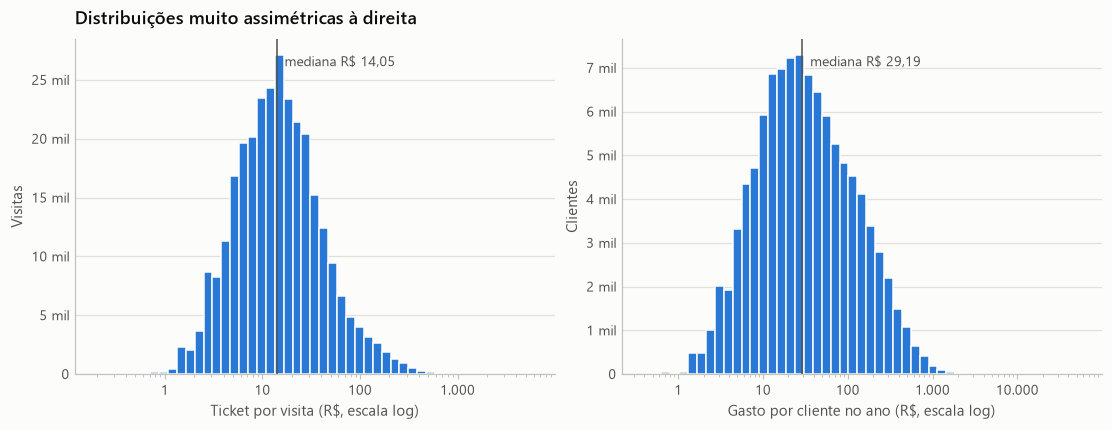

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, serie, rotulo in [
    (axes[0], visitas["FATUR"], "Ticket por visita (R$, escala log)"),
    (axes[1], clientes_ano["gasto"], "Gasto por cliente no ano (R$, escala log)"),
]:
    bins = np.logspace(np.log10(serie.min()), np.log10(serie.max()), 50)
    ax.hist(serie, bins=bins, color=viz.AZUL)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(viz.NUM)
    ax.yaxis.set_major_formatter(viz.MILHAR)
    mediana = serie.median()
    ax.axvline(mediana, color=viz.TINTA_2, linewidth=1)
    ax.annotate(f"mediana {viz.fmt_brl(mediana, 2)}", (mediana, ax.get_ylim()[1] * 0.92),
                xytext=(5, 0), textcoords="offset points", fontsize=9, color=viz.TINTA_2)
    ax.set_xlabel(rotulo)
axes[0].set_ylabel("Visitas")
axes[1].set_ylabel("Clientes")
axes[0].set_title("Distribuições muito assimétricas à direita", loc="left")
viz.salvar(fig, "eda_distribuicao_valores")
plt.show()

As distribuições de valor são fortemente assimétricas (média bem acima da mediana, assimetria e curtose altas): a
mediana e o IQR descrevem melhor o cliente típico, e os atributos monetários pedem escala logarítmica.

### 4.1 Atributos qualitativos

itens  faturamento  % itens  % faturamento
FILIAL RUA       289277    3.801.959    0,520          0,484
       SHOPPING  266921    4.046.767    0,480          0,516
UNID   KG        537634    7.615.712    0,967          0,970
       UN         18564      233.014    0,033          0,030

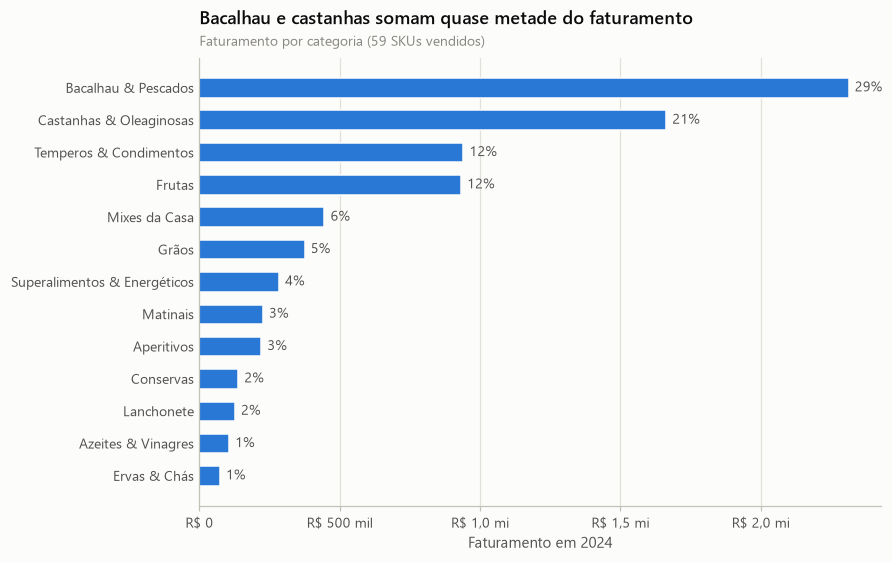

In [11]:
fat_total = itens["FATUR_VENDA"].sum()
display(pd.concat({
    "FILIAL": itens.groupby("FILIAL", observed=True).agg(itens=("COD_VENDA", "size"), faturamento=("FATUR_VENDA", "sum")),
    "UNID": itens.groupby("UNID", observed=True).agg(itens=("COD_VENDA", "size"), faturamento=("FATUR_VENDA", "sum")),
}).assign(**{"% itens": lambda d: d["itens"] / len(itens), "% faturamento": lambda d: d["faturamento"] / fat_total}))

por_categoria = (
    itens.groupby("CATEGORIA", observed=True)
    .agg(faturamento=("FATUR_VENDA", "sum"), clientes=("CLI_CPF", "nunique"), skus=("SKU", "nunique"))
    .sort_values("faturamento")
)
por_categoria["% faturamento"] = por_categoria["faturamento"] / fat_total

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(por_categoria))
ax.barh(y, por_categoria["faturamento"], height=0.6, color=viz.AZUL)
ax.set_yticks(y, por_categoria.index.astype(str))
ax.xaxis.set_major_formatter(viz.BRL)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for yi, (fat, pct) in enumerate(zip(por_categoria["faturamento"], por_categoria["% faturamento"])):
    ax.annotate(viz.fmt_pct(pct), (fat, yi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=viz.TINTA_2)
ax.set_xlabel("Faturamento em 2024")
viz.titulo(ax, "Bacalhau e castanhas somam quase metade do faturamento", "Faturamento por categoria (59 SKUs vendidos)")
viz.salvar(fig, "eda_faturamento_categoria")
plt.show()

## 5. Dinâmica temporal e sazonalidade

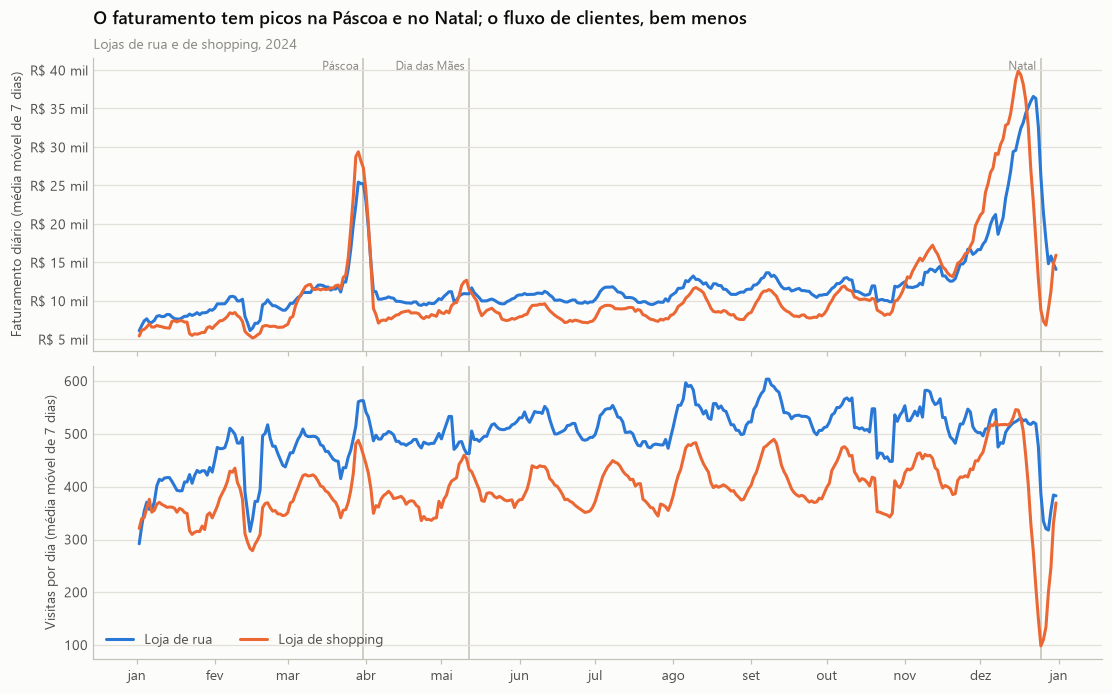

In [12]:
diario = (
    itens.groupby(["DATA_ATEND", "FILIAL"], observed=True)
    .agg(faturamento=("FATUR_VENDA", "sum"), visitas=("CLI_CPF", "nunique"))
    .unstack("FILIAL")
    .reindex(pd.date_range(config.INICIO, config.FIM), fill_value=0)
)
movel = diario.rolling(7, min_periods=1).mean()
eventos = {"Páscoa": "2024-03-31", "Dia das Mães": "2024-05-12", "Natal": "2024-12-25"}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
for ax, medida, formato, rotulo in [
    (axes[0], "faturamento", viz.BRL, "Faturamento diário (média móvel de 7 dias)"),
    (axes[1], "visitas", viz.NUM, "Visitas por dia (média móvel de 7 dias)"),
]:
    for loja, cor in [("RUA", viz.AZUL), ("SHOPPING", viz.LARANJA)]:
        ax.plot(movel.index, movel[(medida, loja)], color=cor, label=f"Loja de {loja.lower()}")
    for nome, dia in eventos.items():
        ax.axvline(pd.Timestamp(dia), color=viz.CONTEXTO, linewidth=1, zorder=0)
    ax.yaxis.set_major_formatter(formato)
    ax.set_ylabel(rotulo, fontsize=9)
for nome, dia in eventos.items():
    axes[0].annotate(nome, (pd.Timestamp(dia), axes[0].get_ylim()[1]), xytext=(-3, -2), textcoords="offset points",
                     ha="right", va="top", fontsize=8, color=viz.TINTA_SUAVE)
axes[1].legend(loc="lower left", ncols=2)
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
viz.titulo(axes[0], "O faturamento tem picos na Páscoa e no Natal; o fluxo de clientes, bem menos",
           "Lojas de rua e de shopping, 2024")
viz.salvar(fig, "eda_serie_diaria")
plt.show()

In [13]:
primeira_visita = visitas.groupby("CLI_CPF")["DATA_ATEND"].min()
mensal = pd.DataFrame({
    "faturamento": itens.groupby(itens["DATA_ATEND"].dt.month)["FATUR_VENDA"].sum(),
    "visitas": visitas.groupby(visitas["DATA_ATEND"].dt.month).size(),
    "clientes ativos": visitas.groupby(visitas["DATA_ATEND"].dt.month)["CLI_CPF"].nunique(),
    "clientes novos*": primeira_visita.dt.month.value_counts(),
    "% faturamento em bacalhau": itens[itens["SAZONAL"]].groupby(itens["DATA_ATEND"].dt.month)["FATUR_VENDA"].sum()
        / itens.groupby(itens["DATA_ATEND"].dt.month)["FATUR_VENDA"].sum(),
}).sort_index()
mensal["ticket médio"] = mensal["faturamento"] / mensal["visitas"]
mensal.index = MESES
mensal

,faturamento,visitas,clientes ativos,clientes novos*,% faturamento em bacalhau,ticket médio
jan,395.488,20484,16949,16949,"0,078","19,307"
fev,411.191,21044,17440,12277,"0,084","19,540"
mar,839.304,24839,20367,11742,"0,496","33,790"
abr,490.214,23227,18959,8840,"0,128","21,105"
mai,543.032,24945,20325,8287,"0,153","21,769"
jun,497.241,24537,20033,7261,"0,109","20,265"
jul,549.079,26005,20921,7156,"0,122","21,114"
ago,611.022,27954,22481,7138,"0,147","21,858"
set,548.319,25361,20740,5986,"0,117","21,621"
out,632.479,26868,21675,5884,"0,189","23,540"


\* "Novo" = primeira visita **observada** na base. Como os dados começam em 02/01/2024, os "novos" de janeiro (e, em
menor grau, de fevereiro e março) incluem clientes antigos — é a **truncagem à esquerda**. A partir de meados do ano o
volume se estabiliza em torno de 6–7 mil clientes novos por mês, uma estimativa melhor da aquisição real.

O número de visitas varia pouco ao longo do ano; o faturamento de março e dezembro dispara por causa do **ticket**, puxado
pelo bacalhau:

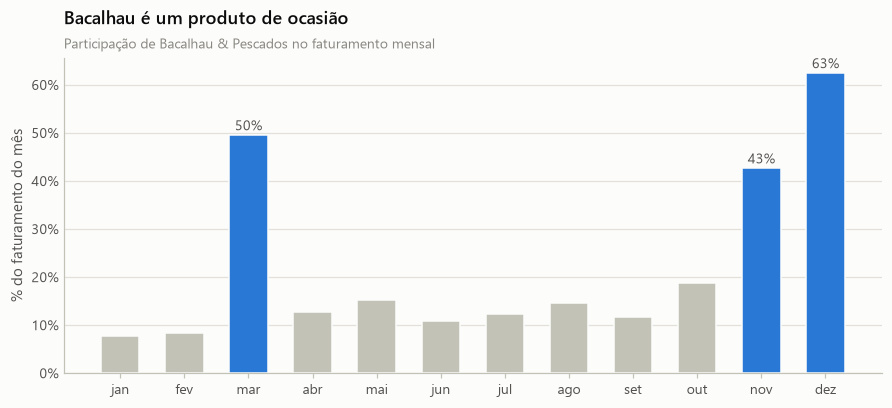

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
destaque = mensal.index.isin(["mar", "nov", "dez"])
cores = np.where(destaque, viz.AZUL, viz.CONTEXTO)
ax.bar(mensal.index, mensal["% faturamento em bacalhau"], color=cores, width=0.6)
for i, (pct, d) in enumerate(zip(mensal["% faturamento em bacalhau"], destaque)):
    if d:
        ax.annotate(viz.fmt_pct(pct), (i, pct), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9, color=viz.TINTA_2)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylabel("% do faturamento do mês")
viz.titulo(ax, "Bacalhau é um produto de ocasião", "Participação de Bacalhau & Pescados no faturamento mensal")
viz.salvar(fig, "eda_bacalhau_mensal")
plt.show()

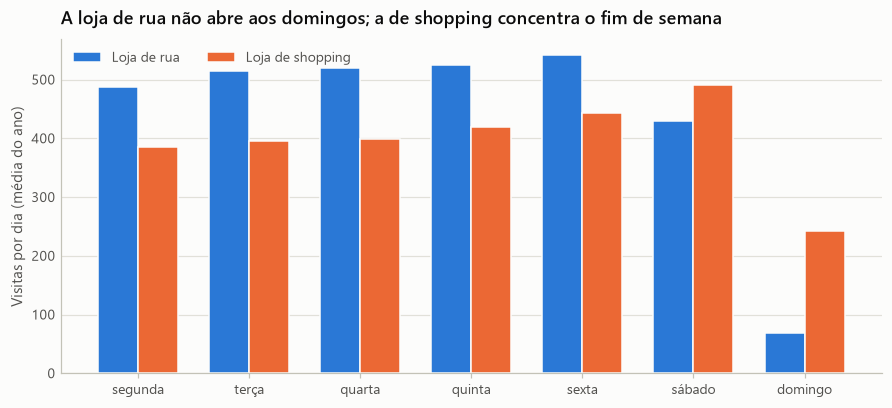

In [15]:
media_dsem = diario["visitas"].groupby(diario.index.day_of_week).mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(7)
largura = 0.36
for desloc, (loja, cor) in zip([-largura / 2, largura / 2], [("RUA", viz.AZUL), ("SHOPPING", viz.LARANJA)]):
    ax.bar(x + desloc, media_dsem[loja].reindex(range(7), fill_value=0), width=largura, color=cor, label=f"Loja de {loja.lower()}")
ax.set_xticks(x, DIAS_SEMANA)
ax.set_ylabel("Visitas por dia (média do ano)")
ax.legend(loc="upper left", ncols=2)
viz.titulo(ax, "A loja de rua não abre aos domingos; a de shopping concentra o fim de semana")
viz.salvar(fig, "eda_dia_semana")
plt.show()

## 6. Visão do cliente

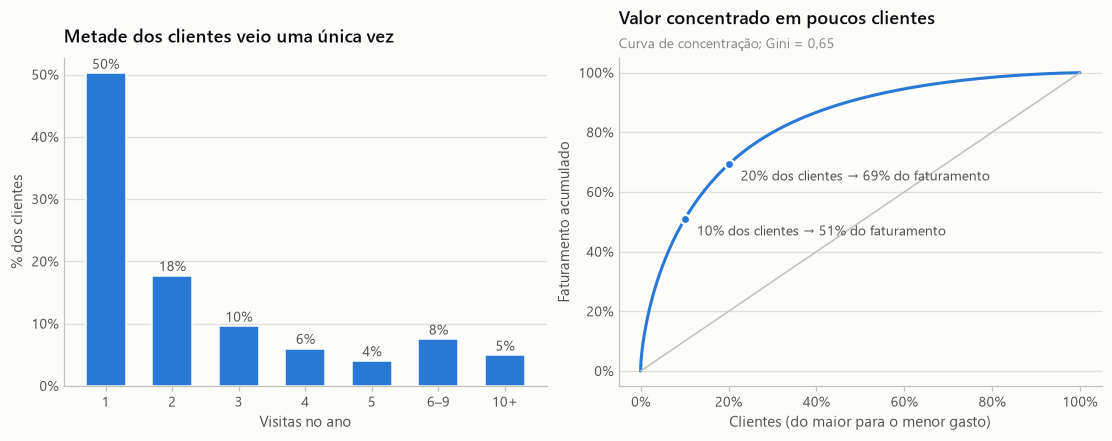

Clientes de visita única: 50.2% | compram nas duas lojas: 2.1%


In [16]:
faixa_visitas = pd.cut(clientes_ano["visitas"], [0, 1, 2, 3, 4, 5, 9, np.inf],
                       labels=["1", "2", "3", "4", "5", "6–9", "10+"])
dist_visitas = faixa_visitas.value_counts(normalize=True).sort_index()

gasto_ordenado = np.sort(clientes_ano["gasto"].to_numpy())[::-1]
acum = np.cumsum(gasto_ordenado) / gasto_ordenado.sum()
frac_clientes = np.arange(1, len(acum) + 1) / len(acum)
lorenz_x = np.concatenate([[0], frac_clientes])
lorenz_y = np.concatenate([[0], acum])
gini = 2 * np.trapezoid(lorenz_y, lorenz_x) - 1

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
ax = axes[0]
ax.bar(dist_visitas.index.astype(str), dist_visitas.values, color=viz.AZUL, width=0.6)
for i, v in enumerate(dist_visitas.values):
    ax.annotate(viz.fmt_pct(v), (i, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=viz.TINTA_2)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Visitas no ano")
ax.set_ylabel("% dos clientes")
viz.titulo(ax, "Metade dos clientes veio uma única vez")

ax = axes[1]
ax.plot(lorenz_x, lorenz_y, color=viz.AZUL)
ax.plot([0, 1], [0, 1], color=viz.CONTEXTO, linewidth=1)
for p in (0.1, 0.2):
    yv = np.interp(p, lorenz_x, lorenz_y)
    ax.plot([p], [yv], marker="o", color=viz.AZUL, markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5)
    ax.annotate(f"{viz.fmt_pct(p)} dos clientes → {viz.fmt_pct(yv)} do faturamento", (p, yv),
                xytext=(8, -4), textcoords="offset points", fontsize=9, color=viz.TINTA_2, va="top")
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Clientes (do maior para o menor gasto)")
ax.set_ylabel("Faturamento acumulado")
viz.titulo(ax, "Valor concentrado em poucos clientes", f"Curva de concentração; Gini = {viz.fmt_num(gini, 2)}")
viz.salvar(fig, "eda_clientes_visitas_concentracao")
plt.show()

lojas_cliente = itens.groupby("CLI_CPF")["FILIAL"].nunique()
print(f"Clientes de visita única: {(clientes_ano['visitas'] == 1).mean():.1%} | "
      f"compram nas duas lojas: {(lojas_cliente > 1).mean():.1%}")

## 7. Coortes de aquisição e retenção

Cada cliente entra na coorte do mês de sua primeira visita observada; a célula (coorte, *k*) mostra a fração da coorte que
voltou a comprar *k* meses depois.

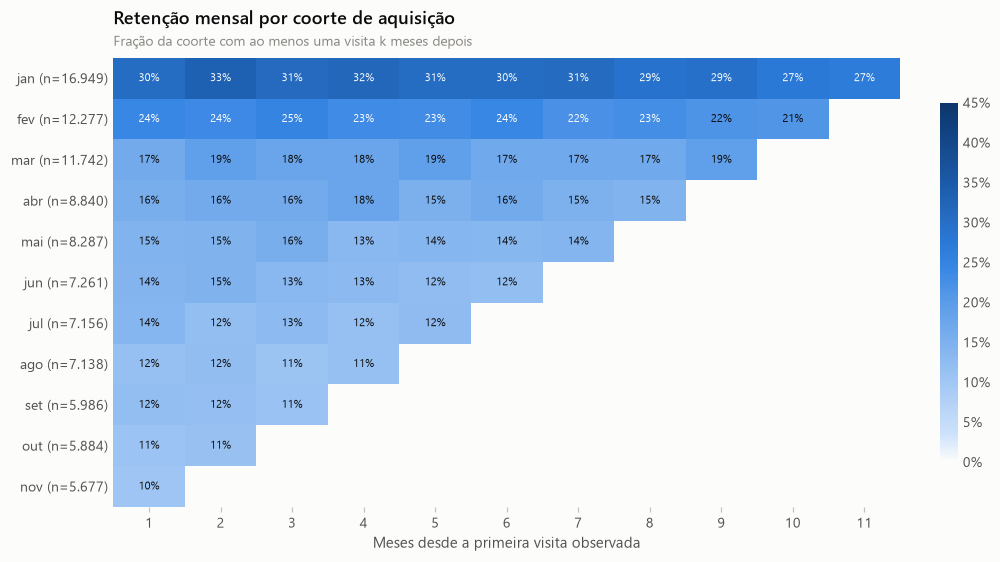

In [17]:
mes_primeira = primeira_visita.dt.year * 12 + primeira_visita.dt.month
v = visitas[["CLI_CPF", "DATA_ATEND"]].copy()
v["coorte"] = v["CLI_CPF"].map(primeira_visita.dt.month)
v["k"] = v["DATA_ATEND"].dt.year * 12 + v["DATA_ATEND"].dt.month - v["CLI_CPF"].map(mes_primeira)
tamanho = primeira_visita.dt.month.value_counts().sort_index()
retencao = v.groupby(["coorte", "k"])["CLI_CPF"].nunique().unstack().div(tamanho, axis=0).loc[:11, 1:]  # dezembro não tem k ≥ 1

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(retencao.to_numpy(dtype=float), cmap=viz.CMAP_SEQ, vmin=0, vmax=0.45, aspect="auto")
for i in range(retencao.shape[0]):
    for j in range(retencao.shape[1]):
        val = retencao.iat[i, j]
        if pd.notna(val):
            ax.text(j, i, viz.fmt_pct(val), ha="center", va="center", fontsize=7.5,
                    color="#ffffff" if val > 0.22 else viz.TINTA)
ax.set_xticks(range(retencao.shape[1]), retencao.columns)
ax.set_yticks(range(retencao.shape[0]), [f"{MESES[c - 1]} (n={viz.fmt_num(tamanho[c])})" for c in retencao.index])
ax.set_xlabel("Meses desde a primeira visita observada")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, format=viz.PCT)
cb.outline.set_visible(False)
viz.titulo(ax, "Retenção mensal por coorte de aquisição", "Fração da coorte com ao menos uma visita k meses depois")
viz.salvar(fig, "eda_coortes")
plt.show()

Depois da primeira visita, só 10–19% de cada coorte (fora janeiro e fevereiro) compra em um dado mês seguinte, e esse
patamar quase não muda com o tempo: a base é feita de muitos clientes ocasionais e de um núcleo recorrente. As coortes
de janeiro e fevereiro retêm mais porque misturam clientes antigos (truncagem à esquerda). A coorte de **março**
(Páscoa) tem um leve repique em dezembro (k = 9), coerente com clientes sazonais — investigado na hipótese H8.

## 8. Intervalo entre visitas e análise de sobrevivência

Para cada visita medimos o tempo até a visita seguinte do mesmo cliente (*inter-purchase time*, IPT). A última visita de
cada cliente não tem sucessora observada: o intervalo é **censurado à direita** em 31/12/2024. Ignorar a censura (usar só
os intervalos completos) subestima os intervalos longos, justamente os que importam para o churn. Por isso usamos o
estimador de **Kaplan–Meier** (Kaplan & Meier, 1958; implementação `lifelines`), em que S(t) = P(próxima visita ocorre
depois de *t* dias).

In [18]:
ipt = visitas[["CLI_CPF", "DATA_ATEND", "ORDEM", "SHOPPING"]].copy()
ipt["PROXIMA"] = ipt.groupby("CLI_CPF")["DATA_ATEND"].shift(-1)
ipt["evento"] = ipt["PROXIMA"].notna()
ipt["duracao"] = np.where(ipt["evento"], (ipt["PROXIMA"] - ipt["DATA_ATEND"]).dt.days,
                          (config.FIM - ipt["DATA_ATEND"]).dt.days)
ipt = ipt[ipt["duracao"] > 0]
ipt["estagio"] = pd.cut(ipt["ORDEM"], [0, 1, 3, np.inf], labels=["1ª visita", "2ª–3ª visita", "4ª visita em diante"])
ipt["loja"] = np.where(ipt["SHOPPING"] >= 0.5, "SHOPPING", "RUA")

km = KaplanMeierFitter().fit(ipt["duracao"], ipt["evento"], label="Todas as visitas")
km_estagio = {e: KaplanMeierFitter().fit(d["duracao"], d["evento"], label=e) for e, d in ipt.groupby("estagio", observed=True)}
km_loja = {l: KaplanMeierFitter().fit(d["duracao"], d["evento"], label=l) for l, d in ipt.groupby("loja")}

completos = np.sort(ipt.loc[ipt["evento"], "duracao"].to_numpy())
grade_t = np.arange(0, 301)
s_ingenuo = 1 - np.searchsorted(completos, grade_t, side="right") / len(completos)

pontos = [7, 14, 30, 60, 90, 120, 180, 270]
tabela_s = pd.DataFrame(
    {nome: m.survival_function_at_times(pontos).to_numpy() for nome, m in {"Todas as visitas": km, **km_estagio}.items()},
    index=pd.Index([f"S({t})" for t in pontos], name="P(intervalo > t)"),
)
tabela_s.loc["mediana (dias)"] = [m.median_survival_time_ for m in [km, *km_estagio.values()]]
tabela_s.loc["n intervalos"] = [len(ipt), *[int(m.event_observed.size) for m in km_estagio.values()]]
tabela_s

,Todas as visitas,1ª visita,2ª–3ª visita,4ª visita em diante
P(intervalo > t),,,,
S(7),"0,909","0,966","0,936","0,834"
S(14),"0,812","0,927","0,859","0,665"
S(30),"0,648","0,840","0,704","0,415"
S(60),"0,483","0,721","0,512","0,218"
S(90),"0,395","0,637","0,397","0,137"
S(120),"0,337","0,573","0,319","0,095"
S(180),"0,270","0,485","0,226","0,056"
S(270),"0,213","0,396","0,154","0,034"
mediana (dias),"56,000","168,000","63,000","24,000"


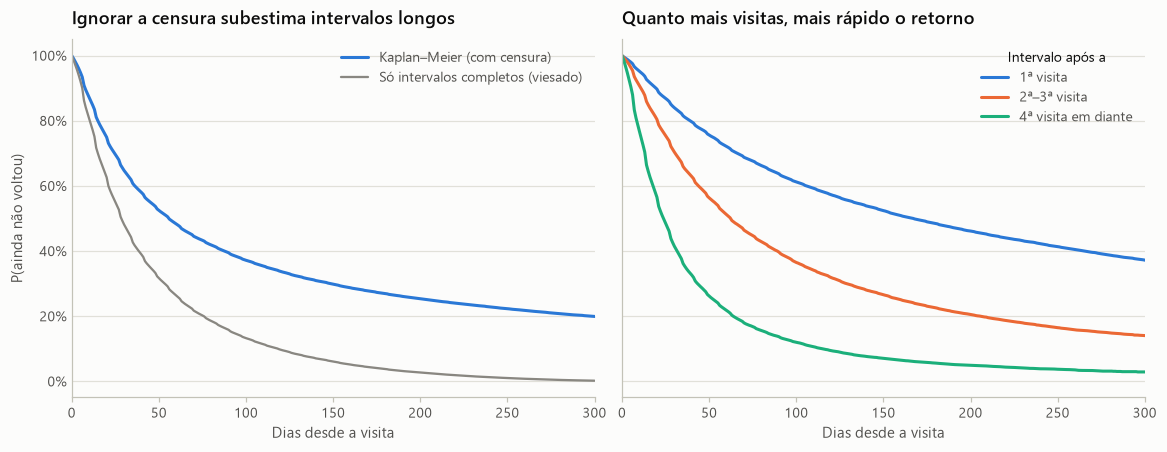

Log-rank entre estágios: χ² = 74.193, p < 0,001
Log-rank entre lojas:    χ² = 1.995, p < 0,001 | mediana rua: 49 dias | mediana shopping: 66 dias


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
ax = axes[0]
sf = km.survival_function_.iloc[:, 0]
ic = km.confidence_interval_
ax.plot(sf.index, sf.values, color=viz.AZUL, label="Kaplan–Meier (com censura)")
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color=viz.AZUL, alpha=0.12, linewidth=0)
ax.plot(grade_t, s_ingenuo, color=viz.TINTA_SUAVE, linewidth=1.5, label="Só intervalos completos (viesado)")
ax.set_xlim(0, 300)
ax.set_xlabel("Dias desde a visita")
ax.set_ylabel("P(ainda não voltou)")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper right")
viz.titulo(ax, "Ignorar a censura subestima intervalos longos")

ax = axes[1]
for (nome, m), cor in zip(km_estagio.items(), [viz.AZUL, viz.LARANJA, viz.VERDE]):
    s = m.survival_function_.iloc[:, 0]
    ax.plot(s.index, s.values, color=cor, label=nome)
ax.set_xlim(0, 300)
ax.set_xlabel("Dias desde a visita")
ax.legend(loc="upper right", title="Intervalo após a")
viz.titulo(ax, "Quanto mais visitas, mais rápido o retorno")
viz.salvar(fig, "eda_km_intervalos")
plt.show()

teste_estagio = multivariate_logrank_test(ipt["duracao"], ipt["estagio"], ipt["evento"])
teste_loja = logrank_test(*(d["duracao"] for _, d in ipt.groupby("loja")), *(d["evento"] for _, d in ipt.groupby("loja")))
print(f"Log-rank entre estágios: χ² = {viz.fmt_num(teste_estagio.test_statistic)}, p {'< 0,001' if teste_estagio.p_value < 0.001 else '= ' + viz.fmt_num(teste_estagio.p_value, 3)}")
print(f"Log-rank entre lojas:    χ² = {viz.fmt_num(teste_loja.test_statistic)}, p {'< 0,001' if teste_loja.p_value < 0.001 else '= ' + viz.fmt_num(teste_loja.p_value, 3)} | "
      + " | ".join(f"mediana {l.lower()}: {m.median_survival_time_:.0f} dias" for l, m in km_loja.items()))

O estágio do relacionamento é o fator que mais separa as curvas: depois da primeira visita, metade dos clientes leva
**mais de cinco meses** para voltar (ou não volta), enquanto clientes com quatro ou mais visitas retornam, em mediana, em
menos de um mês. O teste log-rank confirma diferenças entre estágios e entre lojas — com centenas de milhares de
intervalos, qualquer diferença é "significativa"; o que importa é o tamanho do efeito, visível nas medianas. (Os
intervalos de um mesmo cliente não são independentes, então os p-valores são apenas indicativos.)

## 9. Critério de inatividade (H1)

**Pergunta:** a partir de quantos dias sem comprar faz sentido dizer que o cliente foi perdido?

Pela curva de sobrevivência, a probabilidade de um cliente inativo há *d* dias voltar nos próximos 90 dias é

$$r(d) = P(\text{volta em } (d, d+90] \mid \text{inativo há } d \text{ dias}) = 1 - \frac{S(d+90)}{S(d)}.$$

Se existisse um limiar "natural", *r(d)* despencaria em algum ponto e ficaria estável depois.

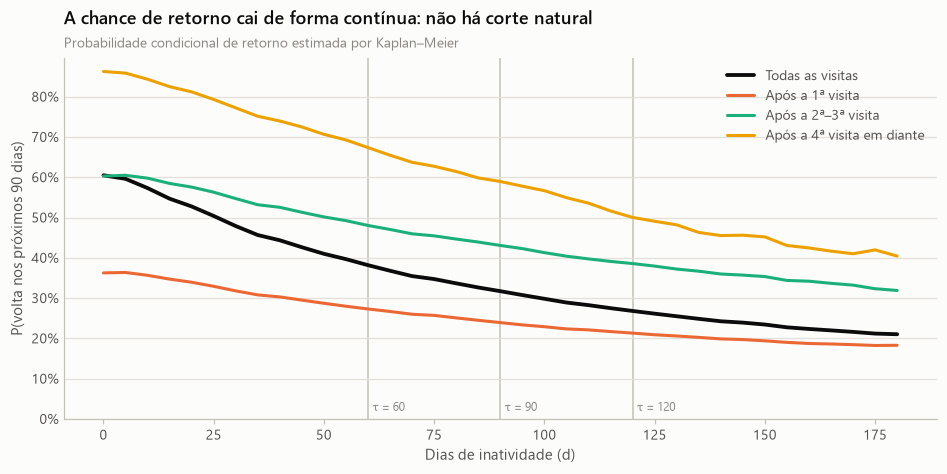

In [20]:
def retorno_condicional(m, d, h=90):
    s = m.survival_function_at_times([d, d + h]).to_numpy()
    return 1 - s[1] / s[0]

grade_d = np.arange(0, 181, 5)
retorno = pd.DataFrame(
    {nome: [retorno_condicional(m, d) for d in grade_d] for nome, m in {"Todas as visitas": km, **km_estagio}.items()},
    index=grade_d,
)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for (nome, serie), cor in zip(retorno.items(), [viz.AZUL, viz.LARANJA, viz.VERDE, viz.AMARELO]):
    if nome == "Todas as visitas":
        ax.plot(serie.index, serie.values, color=viz.TINTA, linewidth=2.5, label=nome)
    else:
        ax.plot(serie.index, serie.values, color=cor, label=f"Após a {nome}")
for t in (60, 90, 120):
    ax.axvline(t, color=viz.CONTEXTO, linewidth=1, zorder=0)
    ax.annotate(f"τ = {t}", (t, 0.02), xytext=(3, 0), textcoords="offset points", fontsize=8, color=viz.TINTA_SUAVE)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Dias de inatividade (d)")
ax.set_ylabel("P(volta nos próximos 90 dias)")
ax.legend(loc="upper right")
viz.titulo(ax, "A chance de retorno cai de forma contínua: não há corte natural",
           "Probabilidade condicional de retorno estimada por Kaplan–Meier")
viz.salvar(fig, "eda_retorno_condicional")
plt.show()

In [21]:
def prevalencia(corte, tau):
    corte = pd.Timestamp(corte)
    ativos = visitas.loc[(visitas["DATA_ATEND"] < corte) & (visitas["DATA_ATEND"] >= corte - pd.Timedelta(days=tau)), "CLI_CPF"].unique()
    voltaram = visitas.loc[(visitas["DATA_ATEND"] >= corte) & (visitas["DATA_ATEND"] < corte + pd.Timedelta(days=tau)), "CLI_CPF"].unique()
    return len(ativos), 1 - np.isin(ativos, voltaram).mean()

def cortes_viaveis(tau):
    # a base ativa exige tau dias de histórico; os atributos, LOOKBACK dias
    lookback = max(config.LOOKBACK, tau)
    inicios = pd.date_range("2024-01-01", "2024-12-01", freq="MS")
    return int(sum((c - pd.Timedelta(days=lookback) >= config.INICIO) and (c + pd.Timedelta(days=tau - 1) <= config.FIM) for c in inicios))

taus = [30, 45, 60, 90, 120, 150, 180]
km_regulares = km_estagio["4ª visita em diante"]
tradeoff = pd.DataFrame(index=pd.Index(taus, name="τ (dias)"))
tradeoff["falso churn: P(volta em 90 d | inativo τ d)"] = [retorno_condicional(km, t) for t in taus]
tradeoff["intervalos de clientes regulares > τ"] = km_regulares.survival_function_at_times(taus).to_numpy()
prev = [prevalencia("2024-07-01", t) for t in taus]
tradeoff["base ativa em 01/07"] = [n for n, _ in prev]
tradeoff["prevalência de churn em 01/07"] = [p for _, p in prev]
tradeoff["snapshots mensais viáveis"] = [cortes_viaveis(t) for t in taus]
tradeoff

,falso churn: P(volta em 90 d | inativo τ d),intervalos de clientes regulares > τ,base ativa em 01/07,prevalência de churn em 01/07,snapshots mensais viáveis
τ (dias),,,,,
30,"0,479","0,415",20033,"0,679",8
45,"0,426","0,291",27048,"0,609",7
60,"0,382","0,218",33617,"0,570",7
90,"0,317","0,137",43397,"0,521",6
120,"0,268","0,095",52322,"0,498",5
150,"0,234","0,071",59215,"0,479",3
180,"0,210","0,056",65217,"0,461",1


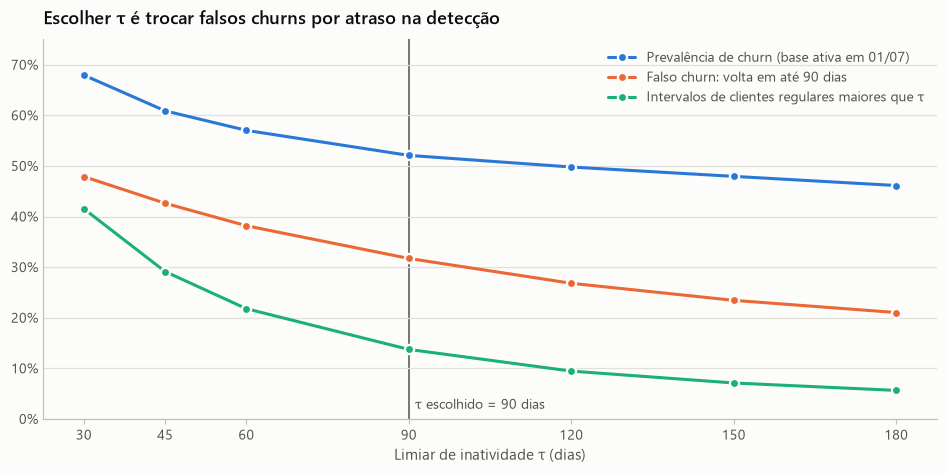

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
series = {
    "Prevalência de churn (base ativa em 01/07)": ("prevalência de churn em 01/07", viz.AZUL),
    "Falso churn: volta em até 90 dias": ("falso churn: P(volta em 90 d | inativo τ d)", viz.LARANJA),
    "Intervalos de clientes regulares maiores que τ": ("intervalos de clientes regulares > τ", viz.VERDE),
}
for rotulo, (col, cor) in series.items():
    ax.plot(tradeoff.index, tradeoff[col], color=cor, marker="o", markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5, label=rotulo)
ax.axvline(90, color=viz.TINTA_2, linewidth=1, zorder=0)
ax.annotate("τ escolhido = 90 dias", (90, 0.02), xytext=(4, 0), textcoords="offset points", fontsize=9, color=viz.TINTA_2)
ax.set_xticks(taus)
ax.set_ylim(0, 0.75)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Limiar de inatividade τ (dias)")
ax.legend(loc="upper right")
viz.titulo(ax, "Escolher τ é trocar falsos churns por atraso na detecção")
viz.salvar(fig, "eda_tradeoff_tau")
plt.show()

### 9.1 Critério global × critério individual

Uma alternativa ao limiar único é um limiar **por cliente**, proporcional ao seu ritmo (por exemplo, três vezes o
intervalo médio entre suas visitas — critério citado na bibliografia do grupo). Comparamos os dois em 01/07/2024 entre
clientes com pelo menos 3 visitas, olhando o que de fato aconteceu nos 90 dias seguintes.

In [23]:
corte_ref = pd.Timestamp("2024-07-01")
antes = visitas[visitas["DATA_ATEND"] < corte_ref]
g = antes.groupby("CLI_CPF")
reg = pd.DataFrame({"visitas": g.size(), "ipt_medio": g["GAP_ANTERIOR"].mean(), "ultima": g["DATA_ATEND"].max()})
reg = reg[reg["visitas"] >= 3].copy()
reg["recencia"] = (corte_ref - reg["ultima"]).dt.days
reg["limiar_individual"] = 3 * reg["ipt_medio"]
voltou = visitas.loc[(visitas["DATA_ATEND"] >= corte_ref) & (visitas["DATA_ATEND"] < corte_ref + pd.Timedelta(days=90)), "CLI_CPF"].unique()
reg["nao_voltou_90d"] = ~reg.index.isin(voltou)

criterios = {"global (90 dias)": reg["recencia"] > 90, "individual (3 × intervalo médio)": reg["recencia"] > reg["limiar_individual"]}
comparacao = pd.DataFrame({
    nome: {
        "clientes marcados como inativos": m.mean(),
        "falso churn (voltaram em 90 dias)": 1 - reg.loc[m, "nao_voltou_90d"].mean(),
        "cobertura (dos que não voltaram, % marcados)": m[reg["nao_voltou_90d"]].mean(),
    }
    for nome, m in criterios.items()
})
display(comparacao)
print(f"Limiar individual mediano: {reg['limiar_individual'].median():.0f} dias "
      f"(P25 = {reg['limiar_individual'].quantile(0.25):.0f}, P75 = {reg['limiar_individual'].quantile(0.75):.0f}) | "
      f"concordância entre critérios (kappa de Cohen) = {viz.fmt_num(cohen_kappa_score(*criterios.values()), 2)}")

,global (90 dias),individual (3 × intervalo médio)
clientes marcados como inativos,"0,060","0,100"
falso churn (voltaram em 90 dias),"0,522","0,583"
"cobertura (dos que não voltaram, % marcados)","0,112","0,164"


Limiar individual mediano: 94 dias (P25 = 65, P75 = 136) | concordância entre critérios (kappa de Cohen) = 0,63


**Decisão: τ = 90 dias**, com análise de sensibilidade para 60 e 120 dias no notebook 2. Justificativa:

1. **Não há corte natural** (H1): *r(d)* decai suavemente; qualquer τ é um compromisso.
2. Para clientes regulares (4+ visitas), ficar 90 dias sem comprar é **anômalo**: só ~14% dos seus intervalos passam disso.
3. A partir de 90 dias os ganhos diminuem: cada 30 dias extras reduzem o falso churn em apenas 2–5 p.p., mas atrasam
   a detecção em um mês inteiro.
4. **Restrição dos dados:** com 1 ano de base e 120 dias de histórico por snapshot, τ = 90 permite 6 snapshots mensais,
   o mínimo para treinar e validar fora do tempo; τ = 180 permitiria um único snapshot.
5. O trimestre é um horizonte natural para planejar ações de retenção.

O critério individual marca clientes mais cedo, mas com mais falsos churns e só faz sentido para quem já tem
histórico; o modelo do notebook 2 incorpora essa ideia como **atributo** (`atraso_relativo`), em vez de usá-la como
definição.

## 10. Hipóteses comportamentais no snapshot de treino (H3–H9)

Construímos o snapshot de **01/05/2024** com o mesmo código do notebook 2 (`churn.features`): base ativa = clientes com
visita nos 90 dias anteriores; atributos = 120 dias anteriores; churn = nenhuma visita nos 90 dias seguintes.
Para cada hipótese medimos a taxa de churn por faixas do atributo, com IC 95% de Wilson. Como efeito, usamos a **AUC
univariada** (0,5 = sem relação; abaixo de 0,5 = associado a menos churn).

In [24]:
snap = features.construir_snapshot(itens, visitas, "2024-05-01")
snap["segmento"] = features.segmento(snap["n_visitas"]).to_numpy()
display(ev.taxa_por_grupo(snap["churn"], snap["segmento"]).assign(**{"% da base": lambda d: d["n"] / len(snap)}))
print(f"Base ativa: {viz.fmt_num(len(snap))} clientes | taxa de churn: {viz.fmt_pct(snap['churn'].mean(), 1)}")

,n,churners,taxa,ic95_inf,ic95_sup,% da base
g,,,,,,
1 visita,24666,16857,"0,683","0,678","0,689","0,583"
2 visitas,8905,3796,"0,426","0,416","0,437","0,211"
3+ visitas,8706,1661,"0,191","0,183","0,199","0,206"


Base ativa: 42.277 clientes | taxa de churn: 52,8%


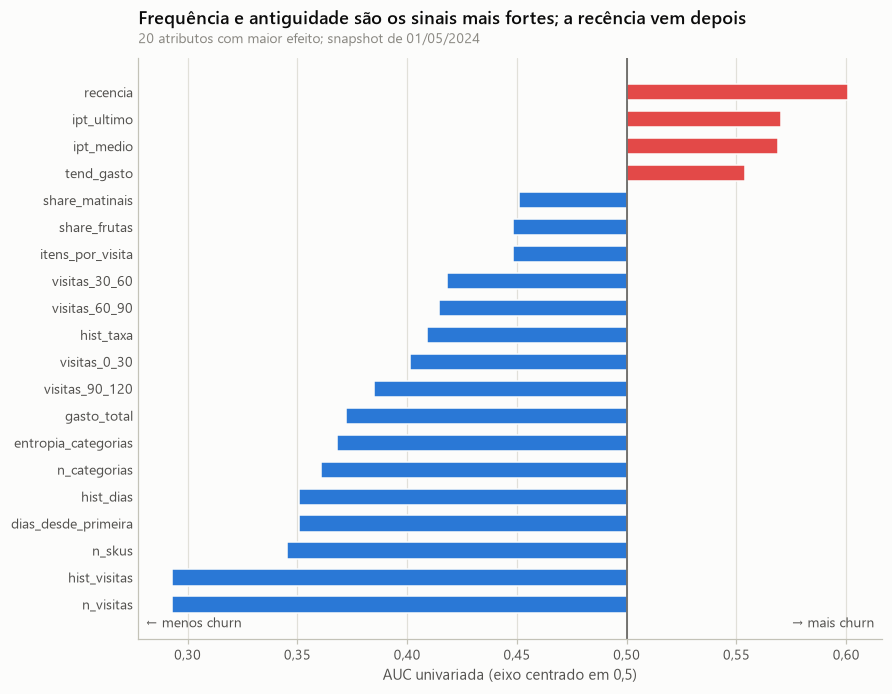

In [25]:
auc_uni = pd.Series({a: ev.auc_univariada(snap["churn"], snap[a]) for a in features.ATRIBUTOS}, name="AUC")
efeito = (auc_uni - 0.5).sort_values(key=np.abs, ascending=False).head(20).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.2))
cores = np.where(efeito > 0, viz.VERMELHO, viz.AZUL)
ax.barh(efeito.index, efeito.values, color=cores, height=0.6)
ax.axvline(0, color=viz.TINTA_2, linewidth=1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: viz.fmt_num(x + 0.5, 2)))
ax.set_xlabel("AUC univariada (eixo centrado em 0,5)")
ax.text(0.99, 0.02, "→ mais churn", transform=ax.transAxes, ha="right", fontsize=9, color=viz.TINTA_2)
ax.text(0.01, 0.02, "← menos churn", transform=ax.transAxes, ha="left", fontsize=9, color=viz.TINTA_2)
viz.titulo(ax, "Frequência e antiguidade são os sinais mais fortes; a recência vem depois",
           "20 atributos com maior efeito; snapshot de 01/05/2024")
viz.salvar(fig, "eda_auc_univariada")
plt.show()

### H3 — recência absoluta × recência relativa ao ritmo do cliente

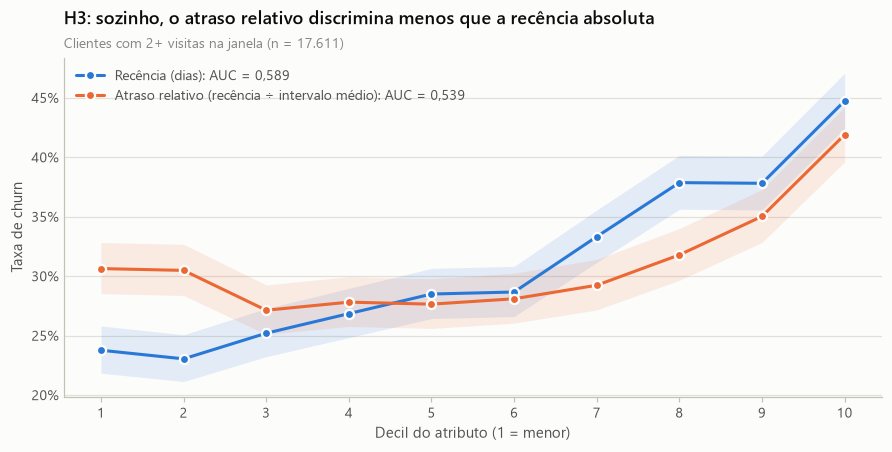

In [26]:
recorrentes = snap[snap["n_visitas"] >= 2]
fig, ax = plt.subplots(figsize=(8, 4))
for col, cor, nome in [("recencia", viz.AZUL, "Recência (dias)"), ("atraso_relativo", viz.LARANJA, "Atraso relativo (recência ÷ intervalo médio)")]:
    decil = pd.qcut(recorrentes[col].rank(method="first"), 10, labels=range(1, 11))
    tab = ev.taxa_por_grupo(recorrentes["churn"], decil)
    viz.linha_ic(ax, np.arange(1, 11), tab, cor=cor, rotulo=f"{nome}: AUC = {viz.fmt_num(ev.auc_univariada(recorrentes['churn'], recorrentes[col]), 3)}")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil do atributo (1 = menor)")
ax.set_ylabel("Taxa de churn")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper left")
viz.titulo(ax, "H3: sozinho, o atraso relativo discrimina menos que a recência absoluta",
           f"Clientes com 2+ visitas na janela (n = {viz.fmt_num(len(recorrentes))})")
viz.salvar(fig, "eda_h3_recencia")
plt.show()

### H4 — frequência e estágio do relacionamento

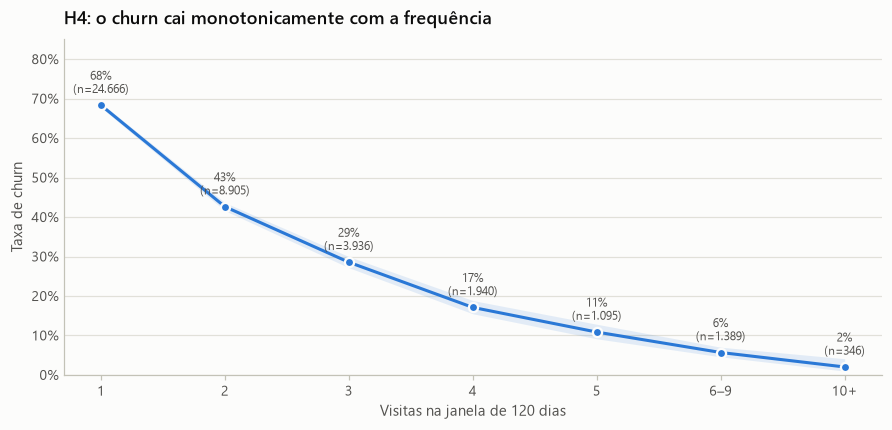

In [27]:
faixa = pd.cut(snap["n_visitas"], [0, 1, 2, 3, 4, 5, 9, np.inf], labels=["1", "2", "3", "4", "5", "6–9", "10+"])
tab_h4 = ev.taxa_por_grupo(snap["churn"], faixa)
fig, ax = plt.subplots(figsize=(8, 3.8))
viz.linha_ic(ax, np.arange(len(tab_h4)), tab_h4)
for i, (taxa, n) in enumerate(zip(tab_h4["taxa"], tab_h4["n"])):
    ax.annotate(f"{viz.fmt_pct(taxa)}\n(n={viz.fmt_num(n)})", (i, taxa), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color=viz.TINTA_2)
ax.set_xticks(range(len(tab_h4)), tab_h4.index.astype(str))
ax.set_ylim(0, 0.85)
ax.set_xlabel("Visitas na janela de 120 dias")
ax.set_ylabel("Taxa de churn")
ax.yaxis.set_major_formatter(viz.PCT)
viz.titulo(ax, "H4: o churn cai monotonicamente com a frequência")
viz.salvar(fig, "eda_h4_frequencia")
plt.show()

### H5, H6, H7 e H9 — regularidade, tendência, amplitude e valor

Frequência confunde quase todas as outras relações (quem vem mais compra mais categorias, gasta mais etc.). Por isso as
comparações são feitas **dentro de estratos de frequência**.

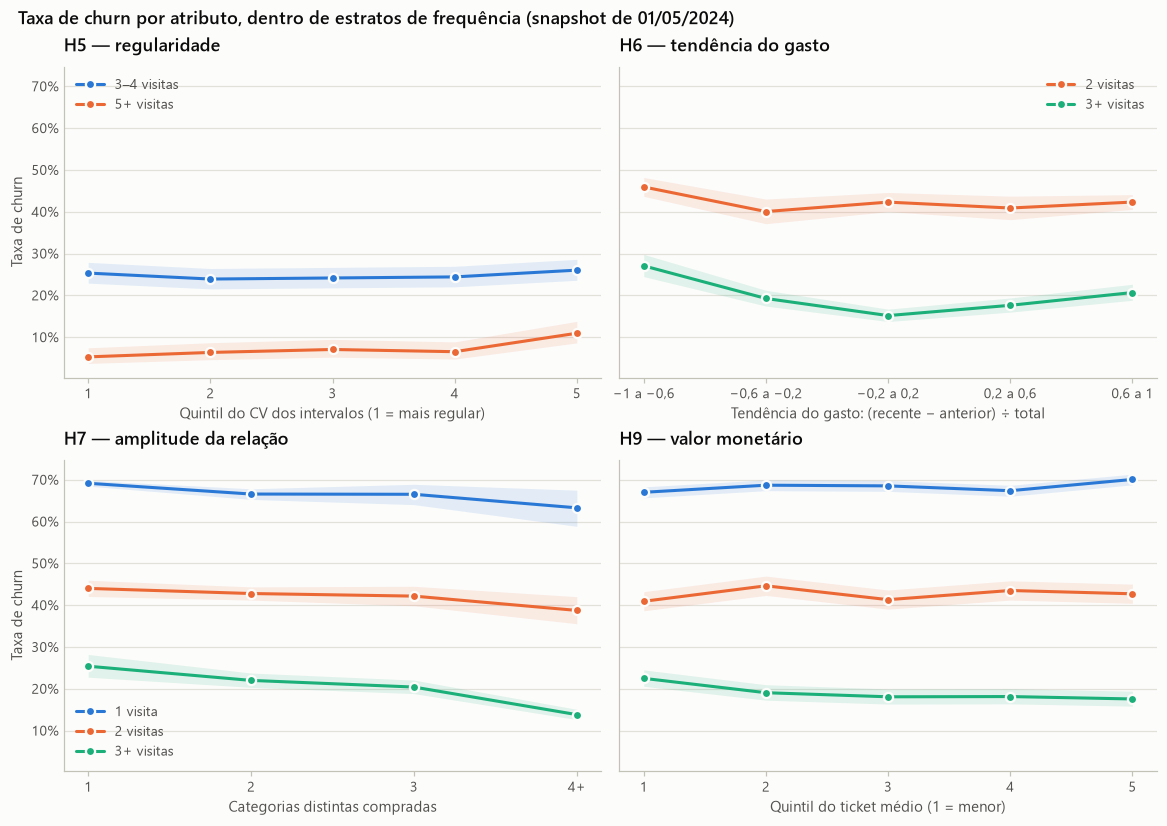

In [28]:
cores_seg = {"1 visita": viz.AZUL, "2 visitas": viz.LARANJA, "3+ visitas": viz.VERDE}
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.4), sharey=True)

# H5 — regularidade (precisa de 3+ visitas)
ax = axes[0, 0]
for nome, d, cor in [("3–4 visitas", snap[snap["n_visitas"].between(3, 4)], viz.AZUL),
                     ("5+ visitas", snap[snap["n_visitas"] >= 5], viz.LARANJA)]:
    quint = pd.qcut(d["ipt_cv"].rank(method="first"), 5, labels=range(1, 6))
    viz.linha_ic(ax, np.arange(1, 6), ev.taxa_por_grupo(d["churn"], quint), cor=cor, rotulo=nome)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Quintil do CV dos intervalos (1 = mais regular)")
ax.legend(loc="upper left")
viz.titulo(ax, "H5 — regularidade")

# H6 — tendência do gasto, normalizada em [−1, 1] (precisa de 2+ visitas)
ax = axes[0, 1]
faixas_t = [-1.001, -0.6, -0.2, 0.2, 0.6, 1.0]
rotulos_t = ["−1 a −0,6", "−0,6 a −0,2", "−0,2 a 0,2", "0,2 a 0,6", "0,6 a 1"]
for seg in ["2 visitas", "3+ visitas"]:
    d = snap[snap["segmento"] == seg]
    faixa_t = pd.cut(d["tend_gasto"], faixas_t, labels=rotulos_t)
    viz.linha_ic(ax, np.arange(5), ev.taxa_por_grupo(d["churn"], faixa_t), cor=cores_seg[seg], rotulo=seg)
ax.set_xticks(range(5), rotulos_t)
ax.set_xlabel("Tendência do gasto: (recente − anterior) ÷ total")
ax.legend(loc="upper right")
viz.titulo(ax, "H6 — tendência do gasto")

# H7 — amplitude (categorias), por estrato
ax = axes[1, 0]
for seg, d in snap.groupby("segmento"):
    cat = pd.cut(d["n_categorias"], [0, 1, 2, 3, np.inf], labels=["1", "2", "3", "4+"])
    viz.linha_ic(ax, np.arange(4), ev.taxa_por_grupo(d["churn"], cat), cor=cores_seg[seg], rotulo=seg)
ax.set_xticks(range(4), ["1", "2", "3", "4+"])
ax.set_xlabel("Categorias distintas compradas")
ax.legend(loc="lower left")
viz.titulo(ax, "H7 — amplitude da relação")

# H9 — ticket médio, por estrato
ax = axes[1, 1]
for seg, d in snap.groupby("segmento"):
    quint = pd.qcut(d["ticket_medio"].rank(method="first"), 5, labels=range(1, 6))
    viz.linha_ic(ax, np.arange(1, 6), ev.taxa_por_grupo(d["churn"], quint), cor=cores_seg[seg], rotulo=seg)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Quintil do ticket médio (1 = menor)")
viz.titulo(ax, "H9 — valor monetário")

for ax in axes.flat:
    ax.yaxis.set_major_formatter(viz.PCT)
for ax in axes[:, 0]:
    ax.set_ylabel("Taxa de churn")
fig.suptitle("Taxa de churn por atributo, dentro de estratos de frequência (snapshot de 01/05/2024)",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
viz.salvar(fig, "eda_h5_h6_h7_h9")
plt.show()

In [29]:
def efeito_por_estrato(col, estratos):
    linhas = {}
    for nome, d in estratos.items():
        d = d.dropna(subset=[col])
        linhas[nome] = {"n": len(d), "AUC": ev.auc_univariada(d["churn"], d[col])}
    return pd.DataFrame(linhas).T

estratos = {"1 visita": snap[snap["n_visitas"] == 1], "2 visitas": snap[snap["n_visitas"] == 2],
            "3+ visitas": snap[snap["n_visitas"] >= 3]}
pd.concat({
    "H5 ipt_cv": efeito_por_estrato("ipt_cv", {"3+ visitas": estratos["3+ visitas"]}),
    "H6 tend_visitas": efeito_por_estrato("tend_visitas", {k: v for k, v in estratos.items() if k != "1 visita"}),
    "H6 tend_gasto": efeito_por_estrato("tend_gasto", {k: v for k, v in estratos.items() if k != "1 visita"}),
    "H7 n_categorias": efeito_por_estrato("n_categorias", estratos),
    "H9 ticket_medio": efeito_por_estrato("ticket_medio", estratos),
}, names=["atributo", "estrato"])

n   AUC
atributo        estrato                
H5 ipt_cv       3+ visitas  8.706 0,493
H6 tend_visitas 2 visitas   8.905 0,486
                3+ visitas  8.706 0,463
H6 tend_gasto   2 visitas   8.905 0,488
                3+ visitas  8.706 0,478
H7 n_categorias 1 visita   24.666 0,486
                2 visitas   8.905 0,486
                3+ visitas  8.706 0,422
H9 ticket_medio 1 visita   24.666 0,511
                2 visitas   8.905 0,506
                3+ visitas  8.706 0,470

### H8 — clientes de ocasião (bacalhau) e churn sazonal

Se parte do churn é sazonal, clientes que compraram bacalhau na Páscoa deveriam sumir no meio do ano e **voltar no
Natal**. Comparamos esses clientes com os demais clientes de março. (Análise descritiva sobre o ano todo; não é usada
para ajustar nenhum modelo.)

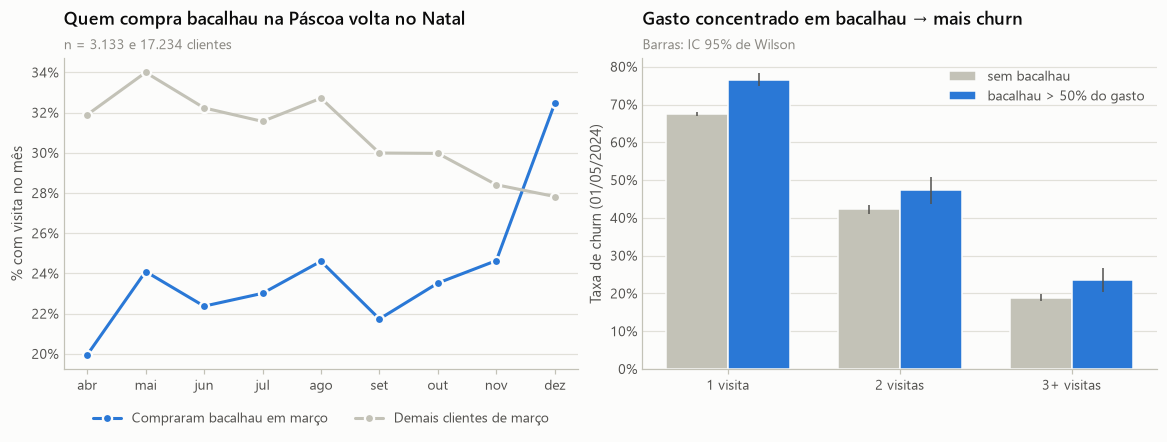

,n,churners,taxa,ic95_inf,ic95_sup
g,,,,,
1 visita | bacalhau > 50% do gasto,2263,1734,"0,766","0,748","0,783"
1 visita | misto,18,9,"0,500","0,290","0,710"
1 visita | sem bacalhau,22385,15114,"0,675","0,669","0,681"
2 visitas | bacalhau > 50% do gasto,752,356,"0,473","0,438","0,509"
2 visitas | misto,42,15,"0,357","0,230","0,508"
2 visitas | sem bacalhau,8111,3425,"0,422","0,412","0,433"
3+ visitas | bacalhau > 50% do gasto,674,158,"0,234","0,204","0,268"
3+ visitas | misto,254,31,"0,122","0,087","0,168"
3+ visitas | sem bacalhau,7778,1472,"0,189","0,181","0,198"


Compradores de bacalhau em março sem visita entre jul e set: 56,9%; destes, 25,5% voltaram a partir de 15/11 (temporada de Natal).


In [30]:
marco = visitas[visitas["DATA_ATEND"].dt.month == 3]
pascoa = marco.loc[marco["SAZONAL"], "CLI_CPF"].unique()
outros = np.setdiff1d(marco["CLI_CPF"].unique(), pascoa)
ativo_mes = visitas.assign(mes=visitas["DATA_ATEND"].dt.month).groupby("mes")["CLI_CPF"].unique()
meses = range(4, 13)
curvas = pd.DataFrame({
    "Compraram bacalhau em março": [np.isin(pascoa, ativo_mes[m]).mean() for m in meses],
    "Demais clientes de março": [np.isin(outros, ativo_mes[m]).mean() for m in meses],
}, index=[MESES[m - 1] for m in meses])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax = axes[0]
for (nome, serie), cor in zip(curvas.items(), [viz.AZUL, viz.CONTEXTO]):
    ax.plot(serie.index, serie.values, color=cor, marker="o", markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5, label=nome)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylabel("% com visita no mês")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
viz.titulo(ax, "Quem compra bacalhau na Páscoa volta no Natal", f"n = {viz.fmt_num(len(pascoa))} e {viz.fmt_num(len(outros))} clientes")

ax = axes[1]
snap["grupo_bacalhau"] = np.select([snap["share_bacalhau"].eq(0), snap["share_bacalhau"].gt(0.5)],
                                   ["sem bacalhau", "bacalhau > 50% do gasto"], default="misto")
tab_b = ev.taxa_por_grupo(snap["churn"], snap["segmento"] + " | " + snap["grupo_bacalhau"])
segs = ["1 visita", "2 visitas", "3+ visitas"]
largura = 0.36
for desloc, (grupo, cor) in zip([-largura / 2, largura / 2], [("sem bacalhau", viz.CONTEXTO), ("bacalhau > 50% do gasto", viz.AZUL)]):
    t = tab_b.loc[[f"{s} | {grupo}" for s in segs]]
    xs = np.arange(3) + desloc
    ax.bar(xs, t["taxa"], width=largura, color=cor, label=grupo)
    ax.errorbar(xs, t["taxa"], yerr=[t["taxa"] - t["ic95_inf"], t["ic95_sup"] - t["taxa"]],
                fmt="none", ecolor=viz.TINTA_2, elinewidth=1)
ax.set_xticks(range(3), segs)
ax.set_ylabel("Taxa de churn (01/05/2024)")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper right")
viz.titulo(ax, "Gasto concentrado em bacalhau → mais churn", "Barras: IC 95% de Wilson")
viz.salvar(fig, "eda_h8_sazonalidade")
plt.show()
display(tab_b)

inativos_jul = ~np.isin(pascoa, visitas.loc[visitas["DATA_ATEND"].between("2024-07-01", "2024-09-28"), "CLI_CPF"].unique())
voltam_natal = np.isin(pascoa, visitas.loc[visitas["DATA_ATEND"] >= "2024-11-15", "CLI_CPF"].unique())
print(f"Compradores de bacalhau em março sem visita entre jul e set: {viz.fmt_pct(inativos_jul.mean(), 1)}; "
      f"destes, {viz.fmt_pct(voltam_natal[inativos_jul].mean(), 1)} voltaram a partir de 15/11 (temporada de Natal).")

### Correlação entre atributos

Correlação de Spearman (robusta a assimetria e a relações monotônicas não lineares) entre os principais atributos.
Rotulamos só as correlações fortes (|ρ| ≥ 0,5).

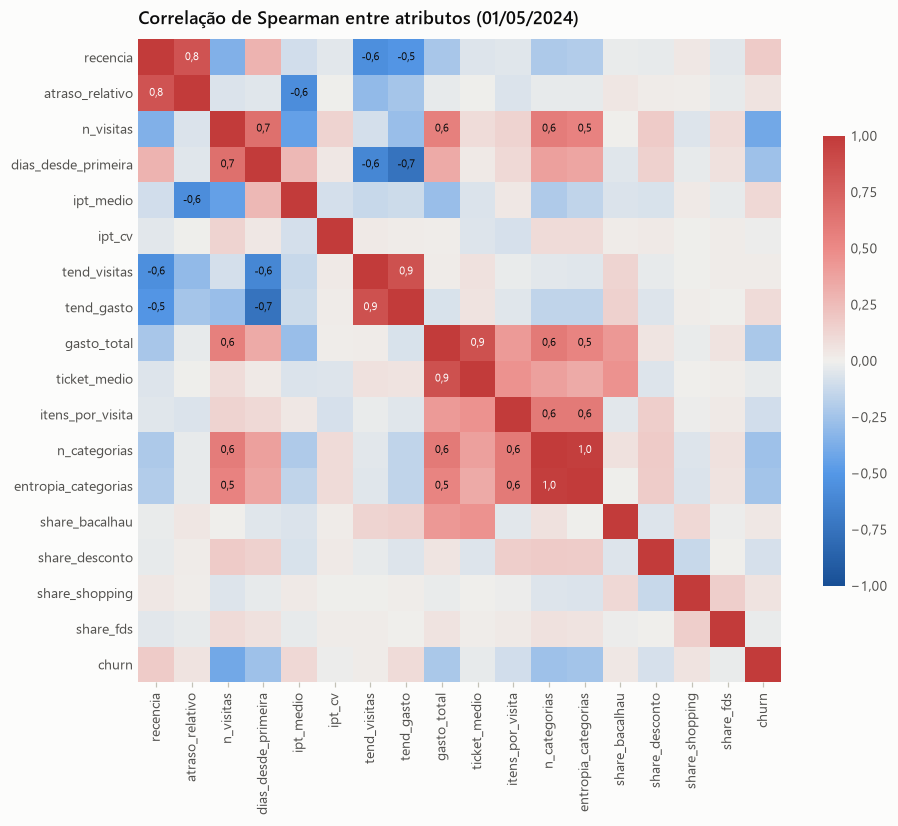

In [31]:
principais = ["recencia", "atraso_relativo", "n_visitas", "dias_desde_primeira", "ipt_medio", "ipt_cv",
              "tend_visitas", "tend_gasto", "gasto_total", "ticket_medio", "itens_por_visita", "n_categorias",
              "entropia_categorias", "share_bacalhau", "share_desconto", "share_shopping", "share_fds", "churn"]
rho = snap[principais].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.6, 7.4))
im = ax.imshow(rho.to_numpy(), cmap=viz.CMAP_DIV, vmin=-1, vmax=1)
for i in range(len(rho)):
    for j in range(len(rho)):
        if i != j and abs(rho.iat[i, j]) >= 0.5:
            ax.text(j, i, viz.fmt_num(rho.iat[i, j], 1), ha="center", va="center", fontsize=7,
                    color="#ffffff" if abs(rho.iat[i, j]) > 0.75 else viz.TINTA)
ax.set_xticks(range(len(rho)), rho.columns, rotation=90)
ax.set_yticks(range(len(rho)), rho.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.outline.set_visible(False)
viz.titulo(ax, "Correlação de Spearman entre atributos (01/05/2024)")
viz.salvar(fig, "eda_correlacao")
plt.show()

## 11. Síntese e decisões para a modelagem

**Caracterização e qualidade.** A base tem 556 mil itens, 297 mil visitas e 103 mil clientes em 2024, sem valores
ausentes nem duplicidades; é um recorte de 59 SKUs (vendidos a granel em 97% dos itens) em duas lojas. As limitações
são pontuais: um dia sem dados (21/10), truncagem à esquerda (a base começa em 02/01) e 10 clientes atípicos com
compras de revenda (1,2% do faturamento), mantidos na base. Uma ressalva de interpretação: como só 59 dos 6.500
produtos estão na base, **a inatividade é medida nesse recorte** — um cliente pode continuar comprando outros itens
da loja e aparecer como inativo aqui.

**Comportamento de compra.** Metade dos clientes comprou uma única vez no ano e 10% dos clientes geram metade do
faturamento (Gini = 0,65). O fluxo de visitas é estável, mas o faturamento tem dois picos sazonais (Páscoa e Natal)
puxados pelo bacalhau, que chega a 63% da receita de dezembro. A loja de rua não abre aos domingos.

**Critério de churn.** O intervalo mediano entre visitas é de 56 dias, mas varia muito com o estágio do cliente
(168 dias após a 1ª visita, 24 dias a partir da 4ª). A probabilidade de retorno cai de forma contínua com a
inatividade, sem ponto de corte natural (**H1 apoiada**). Adotamos **τ = 90 dias**: além de 90 dias os ganhos em falso
churn ficam pequenos, um silêncio desse tamanho é raro para clientes regulares (13,7% dos intervalos) e a base comporta
6 snapshots mensais. A prevalência resultante é de ~52%.

**Hipóteses (evidência preliminar, univariada, snapshot de 01/05/2024):**

| Hipótese | Evidência na EDA | Situação preliminar |
|---|---|---|
| H1 — não há corte natural | *r(d)* decai suavemente de 60% (d = 0) para 21% (d = 180) | apoiada |
| H3 — atraso relativo > recência | entre recorrentes, AUC 0,589 (recência) × 0,539 (atraso relativo) | **não apoiada** isoladamente; reavaliar no modelo multivariado |
| H4 — frequência e estágio | churn de 68% (1 visita) a 2% (10+ visitas); maior efeito univariado | apoiada |
| H5 — regularidade | curva quase plana (AUC 0,49 entre 3+ visitas) | fraca / não apoiada |
| H6 — defecção parcial | dentro dos estratos, gasto em queda → pouco mais churn (AUC 0,46–0,49) | fraca |
| H7 — amplitude (categorias) | dentro de cada estrato, mais categorias → menos churn (25% → 14% entre 3+ visitas) | apoiada |
| H8 — sazonalidade (bacalhau) | gasto dominado por bacalhau → mais churn; 57% dos compradores de março somem no meio do ano e 1 em 4 deles volta no Natal | apoiada |
| H9 — valor monetário fraco | ticket quase não muda a taxa de churn dentro dos estratos (AUC 0,47–0,51) | apoiada |

H2 (robustez a τ) e H10 (modelos) são testadas no notebook 2.

**Decisões para a modelagem:**

1. Rótulo: churn = nenhuma visita nos 90 dias após o corte, para a base ativa (visita nos 90 dias anteriores).
2. Snapshots mensais de 01/05 a 01/10/2024 com validação **fora do tempo** (o rótulo do treino precisa estar
   disponível na data de aplicação).
3. Atributos de janela fixa de 120 dias **e** de histórico acumulado: a frequência e a antiguidade são os sinais mais
   fortes, e limitá-los a 120 dias desperdiça informação.
4. Frequência confunde quase todas as relações: os testes de hipótese finais usam modelos multivariados (regressão
   logística explicativa e SHAP) e resultados por segmento (1, 2 e 3+ visitas).
5. Atributos monetários com escala logarítmica e modelos de árvore, robustos aos clientes atípicos.
6. Sazonalidade é fonte de *drift*: o corte de 01/10 tem o Natal dentro da janela do rótulo, o que deve ser
   discutido nos resultados.